# Anomaly Detection on Machine Acoustic Data

Unsupervised anomaly detection on acoustic emissions from industrial machines,
comparing a classical **feature-based** approach (Part 1) with **one-class
classification** approaches (Part 2). Every detection rule and model is fitted on
**healthy training data only** - anomalous samples are never used for training
or threshold calibration.

- **Part 1 - Feature-based detection on real machine sounds (pump / valve):**
  exploratory analysis of raw signals, spectra and spectrograms; statistical and
  spectral features with percentile thresholds fitted on healthy data; alarm
  overlap (Jaccard) analysis; and a discussion of limitations, cross-machine
  transfer, and the no-anomaly-label regime.
- **Part 2 - Classification-based detection:** MEL-spectrogram features, a dense
  autoencoder scored by reconstruction error, One-Class SVM and Isolation Forest
  on bottleneck features, and a PCA baseline.
- **Extension - Feature fusion:** combining handcrafted features with learned
  (bottleneck / PCA) features under robust scaling, benchmarked across detectors.

## Results (pump_04 machine, test set)

| Approach | AUC |
|---|---|
| Autoencoder reconstruction error | F1 = 0.616 / Acc = 0.695 |
| Bottleneck + One-Class SVM | 0.597 |
| Bottleneck + Isolation Forest | 0.608 |
| PCA (64) + One-Class SVM | 0.895 |
| PCA (64) + Isolation Forest | 0.872 |

Within the fusion study, the handcrafted + PCA combination reaches the best AUC
(0.882 with Isolation Forest), and PCA + One-Class SVM the best threshold-calibrated
F1@95th-percentile (0.50). PCA-compressed spectrograms clearly dominate the
bottleneck features for this machine.

## Data layout

The notebook expects the data in a local `data/` directory (datasets are not
redistributed with this repository):

```
data/
├── machines/pump/{train,test}/*.wav          # machine-sound recordings
├── machines/valve/{train,test}/*.wav
└── mimii/dev_data_pump_04/ ...               # labeled data, MIMII format
    dev_data_valve_00/ ...
```

## Dependencies

`numpy`, `pandas`, `scipy`, `librosa`, `torch`, `scikit-learn`, `seaborn`,
`matplotlib`, `tqdm`.
---


In [25]:
%matplotlib inline

import os
import zipfile

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as scist
from sklearn import metrics
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.svm import OneClassSVM
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from tqdm.notebook import tqdm


## Part 1: Feature-based Anomaly Detection

The goal of this part is to find discriminative features for a real acoustic
dataset recorded on industrial machines.

Acoustic emission and vibration monitoring play integral roles in structural
health monitoring (SHM) by providing crucial insights into the condition and
integrity of structures. Acoustic emission involves the detection of transient
stress waves emitted by materials when they undergo deformation or damage.
Vibration monitoring with accelerometers is widely used to assess the structural
integrity of various systems, from bridges and buildings to rotating machinery.
Vibration analysis can reveal changes in natural frequencies, mode shapes, and
damping characteristics, which can be indicative of structural damage or
degradation.

*Dataset description*

We consider acoustic emissions from two machines: a **pump** and a **valve**.
The data is organized as follows:

* **pump**
    * train set containing recordings of the pump in good working conditions
    * test set containing both healthy recordings and recordings of abnormal behavior
* **valve**
    * train set containing recordings of the valve in good working conditions
    * test set containing both healthy recordings and recordings of abnormal behavior

*Problem description*

Using statistical and spectral features of the acoustic signals, together with
any other features deemed useful, the goal is to identify features that uncover
anomalies present in the test data but absent from the training data. The
selected features are likely to differ between the pump and the valve.

### Analysis steps

1. Plot raw signals, FFT spectra and spectrograms of the healthy pump and valve
   recordings, and highlight the distinctions between the two machines.
2. Visualize raw signals, spectra and spectrograms of the test recordings. Which
   signals look abnormal? Discuss the distinctions between normal and abnormal
   signals. (Performed separately for the pump and the valve.)
3. Compute basic statistical features (mean, variance, skewness, kurtosis) for
   the training and test sets. Which abnormal signals can be detected with
   percentile thresholds fitted on healthy data?
4. Search for a feature, or a combination of features, that uncovers abnormal
   behavior. Analyze whether the selected features raise alarms for the same
   behavior or whether some are specific to particular anomalies (overlap /
   Jaccard analysis).
5. Discuss at least three limitations of the threshold-based method.
6. Consider applying the features and thresholds developed for one machine to a
   different unit of the same type. Would the discriminative power change? How
   can this be mitigated?
7. Finally, consider the scenario in which no anomalous samples are available at
   all. How would you tackle the problem? Outline the proposed approach and
   provide concrete method details.


### 0. Data Setup

The pump and valve recordings are expected on disk under `data/machines/`
(see the [README](#anomaly-detection-on-machine-acoustic-data) for the full
layout). Each machine folder contains `train/` (healthy recordings only) and
`test/` (healthy + abnormal recordings) sub-folders of WAV files.


In [43]:
# Pump recordings -> data/machines/pump/{train,test}/*.wav
os.makedirs("data/machines/pump", exist_ok=True)


In [44]:
# Valve recordings -> data/machines/valve/{train,test}/*.wav
os.makedirs("data/machines/valve", exist_ok=True)


### 1. Extract the Dataset

In [45]:
# List all ZIP files in the current directory
zip_files = [file for file in os.listdir("./data/machines") if file.endswith(".zip")]

# Loop through each ZIP file and unzip it in the same directory
for zip_file in zip_files:
    with zipfile.ZipFile(os.path.join("data/machines", zip_file), "r") as zip_ref:
        zip_ref.extractall("data/machines")

# Delete ZIP archives
for archive in zip_files:
    os.remove(os.path.join("data/machines", archive))


### 2. Load the Audio Data

In this code cell, we are using the `librosa` library to load audio files from two 
directories: `/valve` and `/pump`. The goal is to prepare audio data for further 
analysis or processing.


In [46]:
def load_wav_files(directory: str) -> np.ndarray:
    """Load all .WAV audio files in a directory as a 2D Numpy array

    Args:
        directory (str): Path to the directory containing the audio files

    Returns:
        np.ndarray: Loaded audio files as a 2D array
        np.ndarray: Sampling rates of loaded audio files
    """
    audio_data: list = []

    # Iterate through files in the directory
    for filename in os.listdir(directory):
        if filename.endswith(".wav") or filename.endswith(".WAV"):
            file_path = os.path.join(directory, filename)

            # Load audio file and append it to the list
            audio, sr = librosa.load(file_path, sr=None)
            audio_data.append(audio)

    return np.array(audio_data)


# Paths to the "valve" and "pump" directories
valve_directory = "./data/machines/valve"
pump_directory = "./data/machines/pump"

# Load audio data for "valve" and "pump"
valve_train_data = load_wav_files(os.path.join(valve_directory, "train"))
valve_test_data = load_wav_files(os.path.join(valve_directory, "test"))
pump_train_data = load_wav_files(os.path.join(pump_directory, "train"))
pump_test_data = load_wav_files(os.path.join(pump_directory, "test"))


In [47]:
print(f"Valve Train Data Shape: {valve_train_data.shape}")
print(f"Valve Test Data Shape: {valve_test_data.shape}")
print(f"Pump Train Data Shape: {pump_train_data.shape}")
print(f"Pump Test Data Shape: {pump_test_data.shape}")


Valve Train Data Shape: (500, 160000)
Valve Test Data Shape: (219, 160000)
Pump Train Data Shape: (200, 160000)
Pump Test Data Shape: (200, 160000)


### Implementation


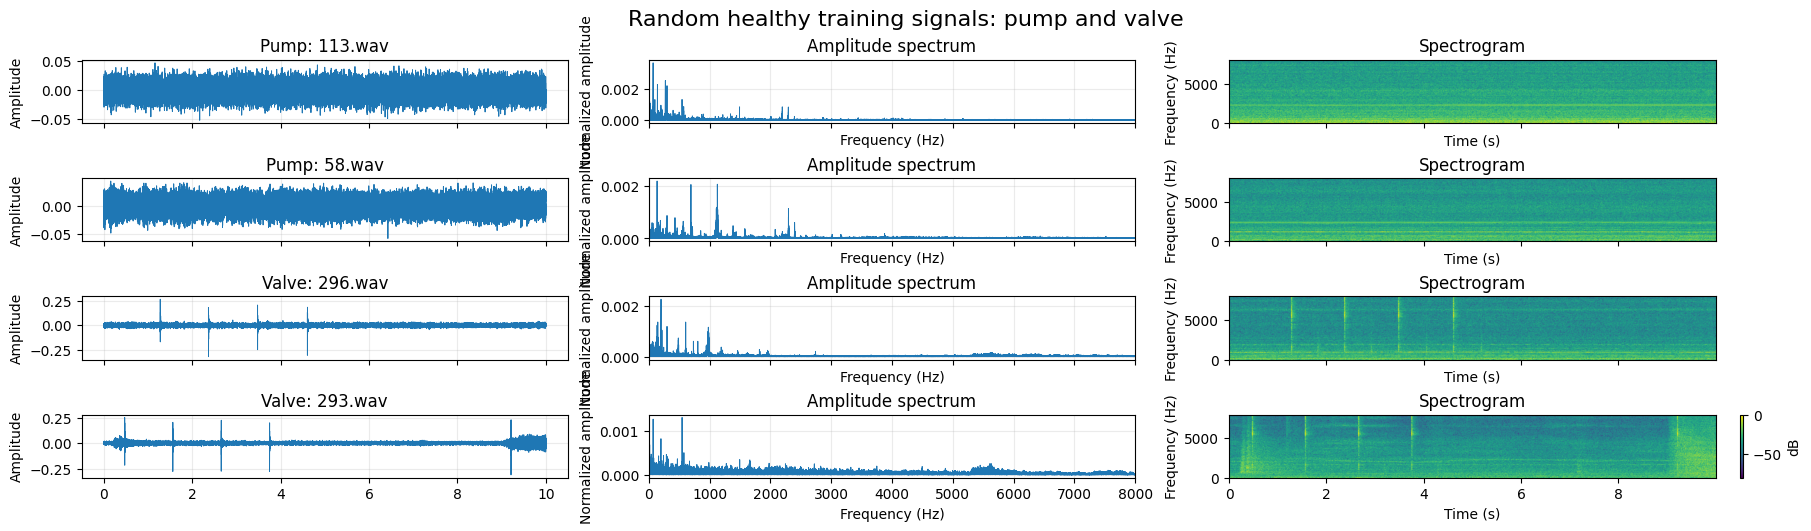

In [49]:
# Randomly select and compare healthy training signals.
# A fixed seed makes the selected recordings reproducible.

rng = np.random.default_rng(42)
num_samples_per_machine = 2
n_fft = 512
hop_length = 128

pump_train_files = sorted(
    os.path.join(pump_directory, "train", filename)
    for filename in os.listdir(os.path.join(pump_directory, "train"))
    if filename.lower().endswith(".wav")
)
valve_train_files = sorted(
    os.path.join(valve_directory, "train", filename)
    for filename in os.listdir(os.path.join(valve_directory, "train"))
    if filename.lower().endswith(".wav")
)

pump_indices = rng.choice(len(pump_train_files), size=num_samples_per_machine, replace=False)
valve_indices = rng.choice(len(valve_train_files), size=num_samples_per_machine, replace=False)

fig, axes = plt.subplots(
    2 * num_samples_per_machine,
    3,
    figsize=(18, 2.6 * num_samples_per_machine),
    sharex="col",
    constrained_layout=True,
)

for machine_name, file_paths, indices in (
    ("Pump", pump_train_files, pump_indices),
    ("Valve", valve_train_files, valve_indices),
):
    for local_row, idx in enumerate(indices):
        row = local_row if machine_name == "Pump" else local_row + num_samples_per_machine
        wav_path = file_paths[idx]
        signal, sampling_rate = librosa.load(wav_path, sr=None)
        time = np.arange(signal.size) / sampling_rate
        filename = os.path.basename(wav_path)

        axes[row, 0].plot(time, signal, linewidth=0.7)
        axes[row, 0].set_title(f"{machine_name}: {filename}")
        axes[row, 0].set_ylabel("Amplitude")
        axes[row, 0].grid(alpha=0.25)

        spectrum = np.abs(np.fft.rfft(signal)) / signal.size
        frequencies = np.fft.rfftfreq(signal.size, d=1.0 / sampling_rate)
        if signal.size > 2:
            spectrum[1:-1] *= 2

        axes[row, 1].plot(frequencies, spectrum, linewidth=0.7)
        axes[row, 1].set_title("Amplitude spectrum")
        axes[row, 1].set_xlabel("Frequency (Hz)")
        axes[row, 1].set_ylabel("Normalized amplitude")
        axes[row, 1].set_xlim(0, sampling_rate / 2)
        axes[row, 1].grid(alpha=0.25)

        stft = librosa.stft(signal, n_fft=n_fft, hop_length=hop_length)
        spectrogram_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)
        image = axes[row, 2].imshow(
            spectrogram_db,
            aspect="auto",
            origin="lower",
            cmap="viridis",
            extent=[0, time[-1], 0, sampling_rate / 2],
        )
        axes[row, 2].set_title("Spectrogram")
        axes[row, 2].set_xlabel("Time (s)")
        axes[row, 2].set_ylabel("Frequency (Hz)")
        axes[row, 2].set_ylim(0, sampling_rate / 2)

fig.colorbar(image, ax=axes[row, 2], label="dB")
fig.suptitle("Random healthy training signals: pump and valve", fontsize=16)
plt.show()


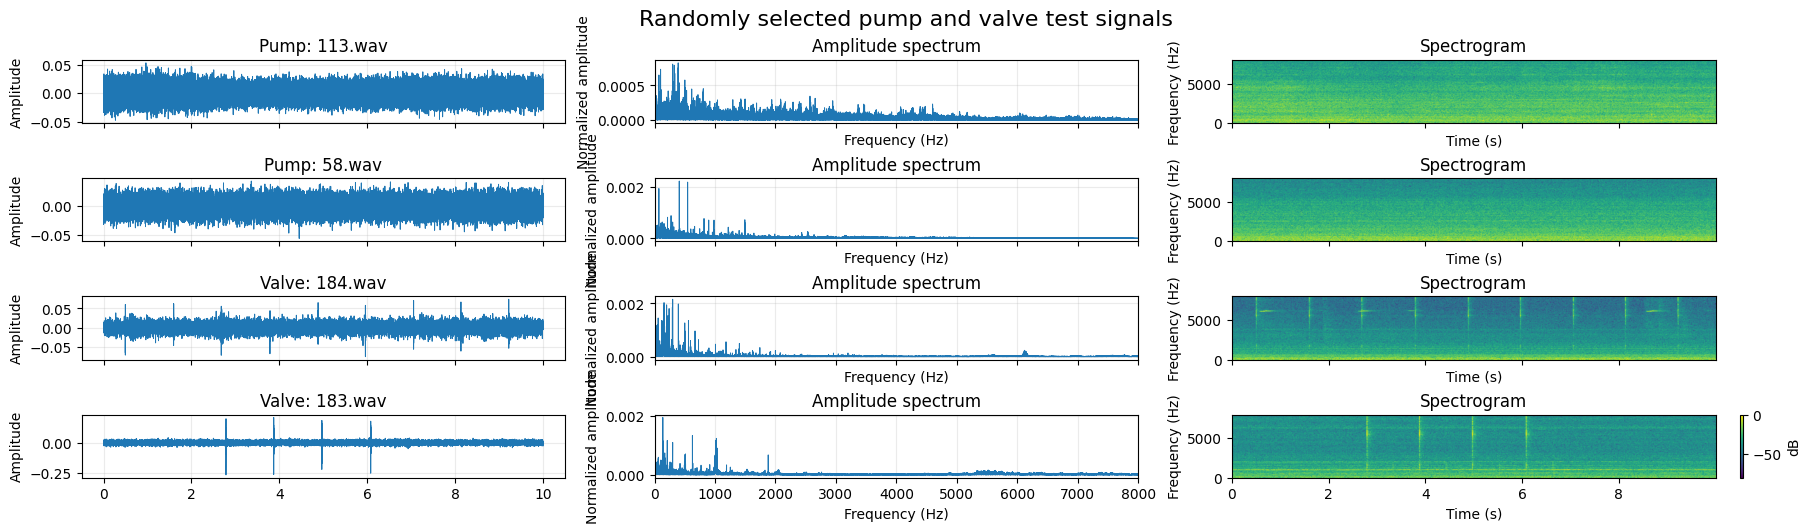

In [50]:
# Randomly select and visualize test signals from both machines.
# A fixed seed makes the selected recordings reproducible.

rng = np.random.default_rng(42)
num_samples_per_machine = 2
n_fft = 512
hop_length = 128

pump_test_files = sorted(
    os.path.join(pump_directory, "test", filename)
    for filename in os.listdir(os.path.join(pump_directory, "test"))
    if filename.lower().endswith(".wav")
)
valve_test_files = sorted(
    os.path.join(valve_directory, "test", filename)
    for filename in os.listdir(os.path.join(valve_directory, "test"))
    if filename.lower().endswith(".wav")
)

pump_test_indices = rng.choice(len(pump_test_files), size=num_samples_per_machine, replace=False)
valve_test_indices = rng.choice(len(valve_test_files), size=num_samples_per_machine, replace=False)

fig, axes = plt.subplots(
    2 * num_samples_per_machine,
    3,
    figsize=(18, 2.6 * num_samples_per_machine),
    sharex="col",
    constrained_layout=True,
)

for machine_name, file_paths, indices in (
    ("Pump", pump_test_files, pump_test_indices),
    ("Valve", valve_test_files, valve_test_indices),
):
    for local_row, idx in enumerate(indices):
        row = local_row if machine_name == "Pump" else local_row + num_samples_per_machine
        wav_path = file_paths[idx]
        signal, sampling_rate = librosa.load(wav_path, sr=None)
        time = np.arange(signal.size) / sampling_rate
        filename = os.path.basename(wav_path)

        axes[row, 0].plot(time, signal, linewidth=0.7)
        axes[row, 0].set_title(f"{machine_name}: {filename}")
        axes[row, 0].set_ylabel("Amplitude")
        axes[row, 0].grid(alpha=0.25)

        spectrum = np.abs(np.fft.rfft(signal)) / signal.size
        frequencies = np.fft.rfftfreq(signal.size, d=1.0 / sampling_rate)
        if signal.size > 2:
            spectrum[1:-1] *= 2

        axes[row, 1].plot(frequencies, spectrum, linewidth=0.7)
        axes[row, 1].set_title("Amplitude spectrum")
        axes[row, 1].set_xlabel("Frequency (Hz)")
        axes[row, 1].set_ylabel("Normalized amplitude")
        axes[row, 1].set_xlim(0, sampling_rate / 2)
        axes[row, 1].grid(alpha=0.25)

        stft = librosa.stft(signal, n_fft=n_fft, hop_length=hop_length)
        spectrogram_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)
        image = axes[row, 2].imshow(
            spectrogram_db,
            aspect="auto",
            origin="lower",
            cmap="viridis",
            extent=[0, time[-1], 0, sampling_rate / 2],
        )
        axes[row, 2].set_title("Spectrogram")
        axes[row, 2].set_xlabel("Time (s)")
        axes[row, 2].set_ylabel("Frequency (Hz)")
        axes[row, 2].set_ylim(0, sampling_rate / 2)

fig.colorbar(image, ax=axes[row, 2], label="dB")
fig.suptitle("Randomly selected pump and valve test signals", fontsize=16)
plt.show()


In [51]:
import numpy as np
import pandas as pd
from scipy import stats


def extract_features(data):
    """Extract statistical and spectral features from each recording."""
    data = np.asarray(data)
    if data.ndim == 1:
        data = data.reshape(1, -1)

    fft_vals = np.abs(np.fft.rfft(data, axis=1))
    return pd.DataFrame(
        {
            "Mean": np.mean(data, axis=1),
            "Variance": np.var(data, axis=1),
            "Skewness": stats.skew(data, axis=1),
            "Kurtosis": stats.kurtosis(data, axis=1),
            "MaxAbs": np.max(np.abs(data), axis=1),
            "SpSkew": stats.skew(fft_vals, axis=1),
        }
    )


quantiles = [0.5, 99.5]
feature_names = ["Mean", "Variance", "Skewness", "Kurtosis", "MaxAbs", "SpSkew"]
machine_data = {
    "Pump": (pump_train_data, pump_test_data),
    "Valve": (valve_train_data, valve_test_data),
}
feature_results = {}

for machine_name, (train_data, test_data) in machine_data.items():
    train_features = extract_features(train_data)
    test_features = extract_features(test_data)
    limits = {
        name: np.percentile(train_features[name], quantiles)
        for name in feature_names
    }
    train_flags = {
        name: np.flatnonzero(
            (train_features[name] < limits[name][0])
            | (train_features[name] > limits[name][1])
        )
        for name in feature_names
    }
    test_flags = {
        name: np.flatnonzero(
            (test_features[name] < limits[name][0])
            | (test_features[name] > limits[name][1])
        )
        for name in feature_names
    }

    train_counts = np.column_stack(
        [train_features[name].lt(limits[name][0]) | train_features[name].gt(limits[name][1])
         for name in feature_names]
    ).sum(axis=1)
    test_counts = np.column_stack(
        [test_features[name].lt(limits[name][0]) | test_features[name].gt(limits[name][1])
         for name in feature_names]
    ).sum(axis=1)

    feature_results[machine_name] = {
        "train": train_features,
        "test": test_features,
        "limits": limits,
        "train_flags": train_flags,
        "test_flags": test_flags,
        "train_flag_counts": train_counts,
        "test_flag_counts": test_counts,
    }

    n_train, n_test = len(train_features), len(test_features)

    def report(dataset_label, features, flags, counts, n_samples):
        width = 40
        title = f" {machine_name.upper()} \u2013 {dataset_label} ({n_samples} samples) "
        print("\u2554" + "\u2550" * width + "\u2557")
        print("\u2551" + title.center(width) + "\u2551")
        print("\u2560" + "\u2550" * width + "\u2563")
        print("\u2551 " + "Feature".ljust(12) + "Anomalies".rjust(9) + "    Share".rjust(9) + "  \u2551")
        print("\u2560" + "\u2500" * width + "\u2563")
        for name in feature_names:
            n = len(flags[name])
            share = n / n_samples * 100
            line = f" {name.ljust(12)}{str(n).rjust(9)}{share:9.1f}%   "
            print("\u2551" + line.ljust(width) + " \u2551")
        print("\u2560" + "\u2500" * width + "\u2563")
        print("\u2551 Samples flagged by at least k features:   \u2551")
        max_count = max(1, max((counts >= k).sum() for k in range(1, len(feature_names) + 1)))
        for k in range(1, len(feature_names) + 1):
            n = int((counts >= k).sum())
            bar = "\u2588" * round(n / max_count * 12)
            line = f"  k\u2265{k}  {str(n).rjust(5)}  {bar:<12}"
            print("\u2551" + line.ljust(width) + " \u2551")
        print("\u255a" + "\u2550" * width + "\u255d")
        print()

    report("Training", train_features, train_flags, train_counts, n_train)
    report("Test", test_features, test_flags, test_counts, n_test)


╔════════════════════════════════════════╗
║     PUMP – Training (200 samples)      ║
╠════════════════════════════════════════╣
║ Feature     Anomalies    Share  ║
╠────────────────────────────────────────╣
║ Mean                2      1.0%         ║
║ Variance            2      1.0%         ║
║ Skewness            2      1.0%         ║
║ Kurtosis            2      1.0%         ║
║ MaxAbs              2      1.0%         ║
║ SpSkew              2      1.0%         ║
╠────────────────────────────────────────╣
║ Samples flagged by at least k features:   ║
║  k≥1     11  ████████████               ║
║  k≥2      1  █                          ║
║  k≥3      0                             ║
║  k≥4      0                             ║
║  k≥5      0                             ║
║  k≥6      0                             ║
╚════════════════════════════════════════╝

╔════════════════════════════════════════╗
║       PUMP – Test (200 samples)        ║
╠════════════════════════════════════════╣
║ 

In [52]:
for machine_name, results in feature_results.items():
    test_flags = results["test_flags"]
    feature_names = list(test_flags)
    flag_sets = {name: set(test_flags[name]) for name in feature_names}
    overlap = pd.DataFrame(0, index=feature_names, columns=feature_names)
    jaccard = pd.DataFrame(0.0, index=feature_names, columns=feature_names)

    for first in feature_names:
        for second in feature_names:
            shared = flag_sets[first] & flag_sets[second]
            union = flag_sets[first] | flag_sets[second]
            overlap.loc[first, second] = len(shared)
            jaccard.loc[first, second] = len(shared) / len(union) if union else 0.0

    print(f"{machine_name}: pairwise test-alarm overlap counts")
    display(overlap)
    print(f"{machine_name}: pairwise test-alarm Jaccard similarity")
    display(jaccard.round(2))

Pump: pairwise test-alarm overlap counts


,Mean,Variance,Skewness,Kurtosis,MaxAbs,SpSkew
Mean,0,0,0,0,0,0
Variance,0,20,2,5,1,1
Skewness,0,2,5,4,1,3
Kurtosis,0,5,4,12,3,4
MaxAbs,0,1,1,3,6,2
SpSkew,0,1,3,4,2,13


Pump: pairwise test-alarm Jaccard similarity


,Mean,Variance,Skewness,Kurtosis,MaxAbs,SpSkew
Mean,0.0,0.00,0.00,0.00,0.00,0.00
Variance,0.0,1.00,0.09,0.19,0.04,0.03
Skewness,0.0,0.09,1.00,0.31,0.10,0.20
Kurtosis,0.0,0.19,0.31,1.00,0.20,0.19
MaxAbs,0.0,0.04,0.10,0.20,1.00,0.12
SpSkew,0.0,0.03,0.20,0.19,0.12,1.00


Valve: pairwise test-alarm overlap counts


,Mean,Variance,Skewness,Kurtosis,MaxAbs,SpSkew
Mean,5,2,0,2,2,0
Variance,2,120,0,120,119,2
Skewness,0,0,1,0,0,0
Kurtosis,2,120,0,123,119,2
MaxAbs,2,119,0,119,121,2
SpSkew,0,2,0,2,2,4


Valve: pairwise test-alarm Jaccard similarity


,Mean,Variance,Skewness,Kurtosis,MaxAbs,SpSkew
Mean,1.00,0.02,0.0,0.02,0.02,0.00
Variance,0.02,1.00,0.0,0.98,0.98,0.02
Skewness,0.00,0.00,1.0,0.00,0.00,0.00
Kurtosis,0.02,0.98,0.0,1.00,0.95,0.02
MaxAbs,0.02,0.98,0.0,0.95,1.00,0.02
SpSkew,0.00,0.02,0.0,0.02,0.02,1.00


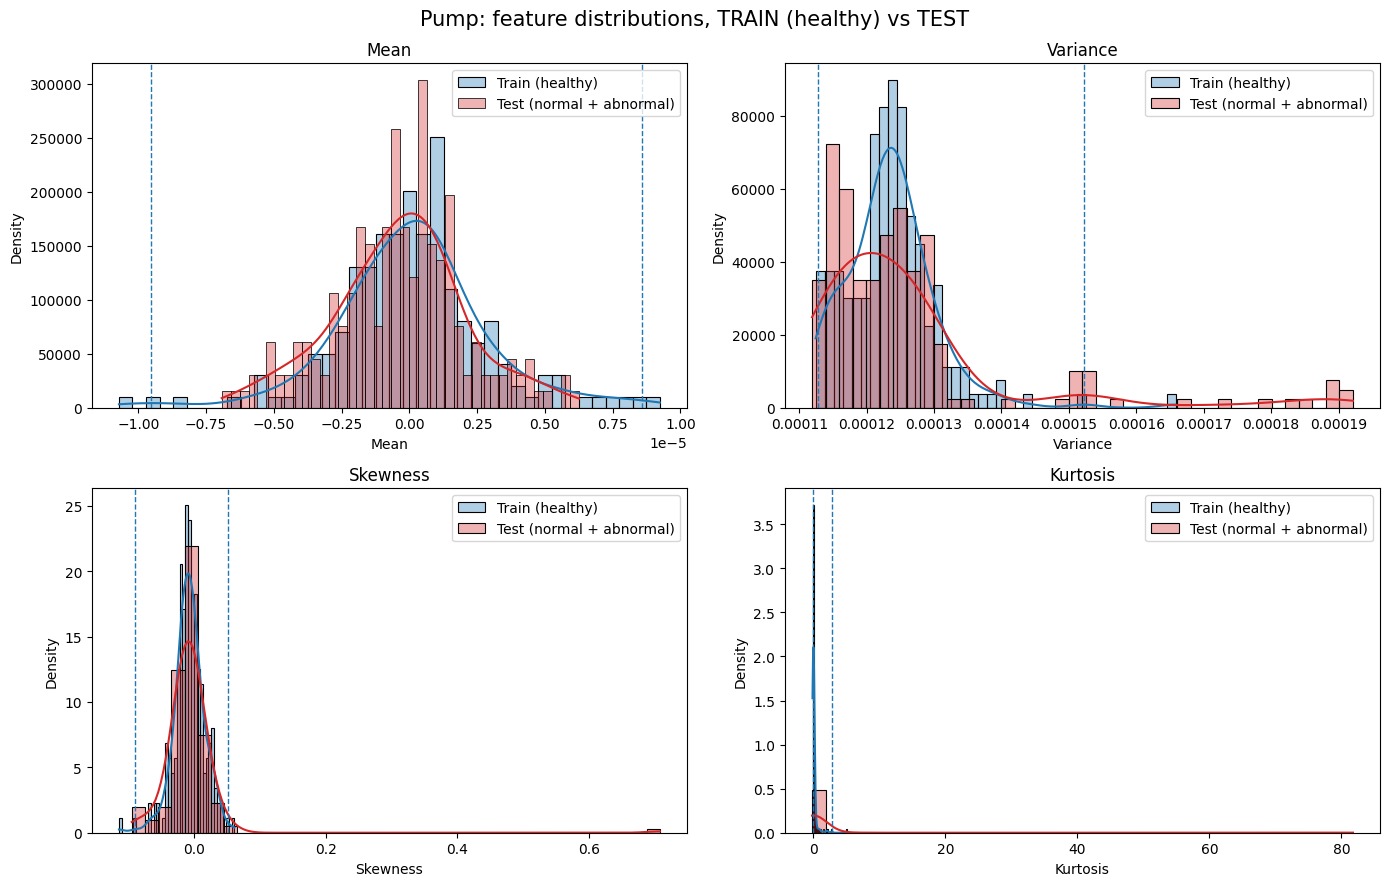

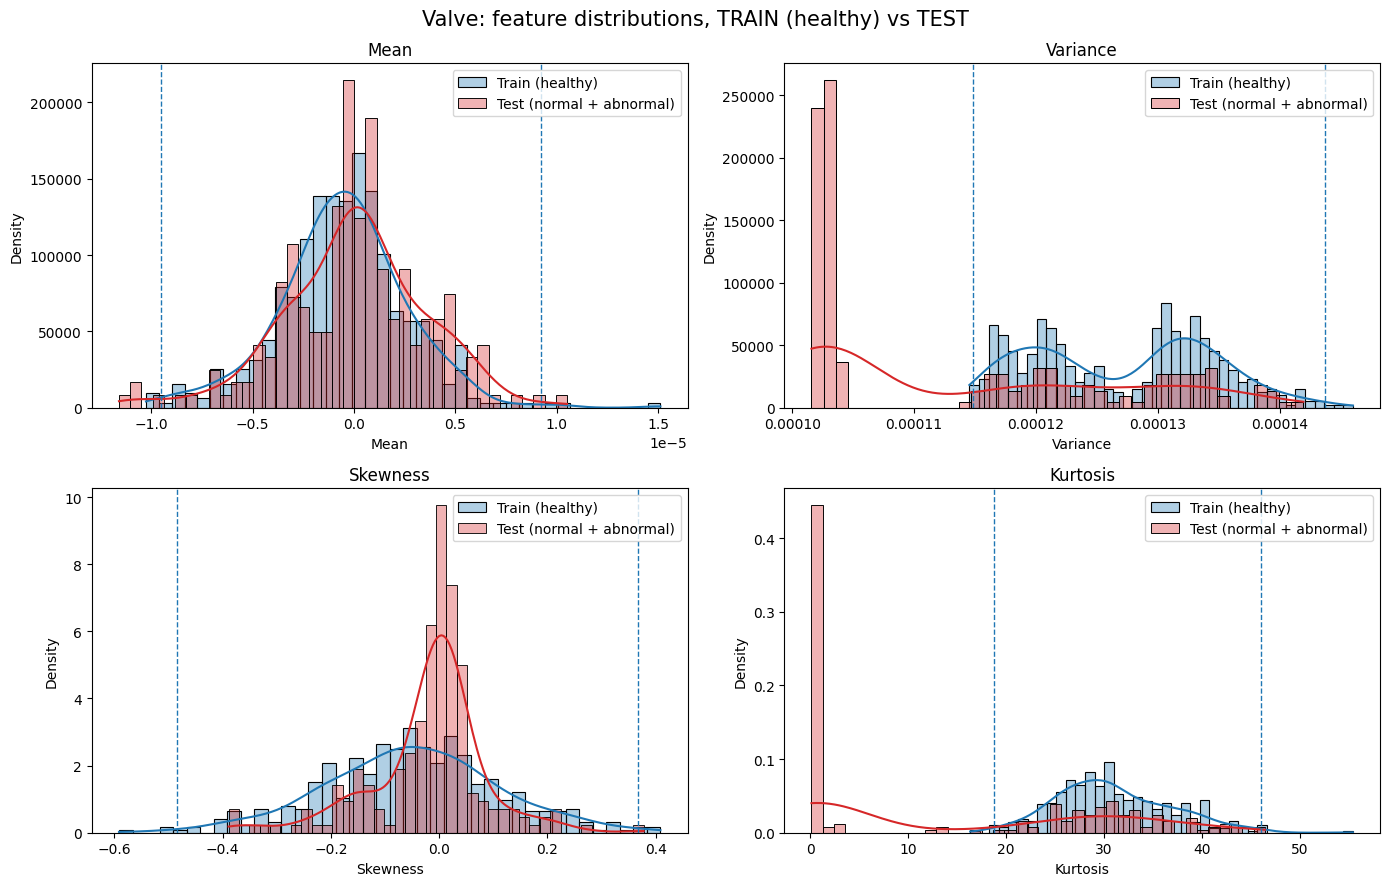

In [53]:
# Visualize the distribution of each basic statistical feature for TRAIN vs TEST.


basic_features = ["Mean", "Variance", "Skewness", "Kurtosis"]

for machine_name, results in feature_results.items():
    train_features = results["train"]
    test_features = results["test"]
    limits = results["limits"]

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle(
        f"{machine_name}: feature distributions, TRAIN (healthy) vs TEST",
        fontsize=15,
    )

    for ax, name in zip(axes.ravel(), basic_features):
        sns.histplot(
            train_features[name],
            kde=True,
            stat="density",
            bins=40,
            color="tab:blue",
            alpha=0.35,
            label="Train (healthy)",
            ax=ax,
        )
        sns.histplot(
            test_features[name],
            kde=True,
            stat="density",
            bins=40,
            color="tab:red",
            alpha=0.35,
            label="Test (normal + abnormal)",
            ax=ax,
        )
        ax.axvline(limits[name][0], color="tab:blue", ls="--", lw=1)
        ax.axvline(limits[name][1], color="tab:blue", ls="--", lw=1)
        ax.set_title(name)
        ax.set_xlabel(name)
        ax.set_ylabel("Density")
        ax.legend()

    fig.tight_layout()
    plt.show()


## Part 2: Classification-based Anomaly Detection

We now treat anomaly detection as a **one-class classification** problem, where
the model is trained on normal sound data to detect deviations from the learned
pattern.

Anomalous sound detection can be achieved with the following steps:
   - Feature Extraction (I)
   - One-class Classifier Training (II)
   - Decisions based on a threshold from the trained classifier (III)

This part focuses on tasks (I) and (II). The quality of the one-class
classifier is assessed using the **Area Under the Curve (AUC)** score on the
test dataset.

The model used here is a type of neural network called an **AutoEncoder**
(AE). The AE is trained to reconstruct its input while compressing it into a
lower-dimensional latent space, minimizing information loss in the process.
The feature extraction and the network architecture are then modified to
improve anomalous-sound detection performance.

### Experiments

Each experiment is run separately for the pump and valve datasets.

1. Extract MEL-spectrogram features, train a simple AutoEncoder that
   reconstructs the input MEL-spectrogram, fix a threshold on the
   reconstruction loss, and report accuracy, TPR, FPR, F1-score and AUC.
2. From the trained AutoEncoder, take the bottleneck features and train
   (1) a One-Class SVM and (2) an Isolation Forest; report the same metrics.
3. Project the MEL-spectrogram into a smaller space with PCA and train
   (1) a One-Class SVM and (2) an Isolation Forest on the PCA features;
   report the same metrics.
4. Compare the five feature/detector combinations on test performance,
   identify the best combination, and discuss the advantages and limitations
   of each approach.

**Extension:** investigate whether combining the handcrafted features developed
in Part 1 with the feature representations learned in Part 2 improves detection.
A feature-fusion strategy (e.g. Part 1 features + bottleneck or PCA features)
is designed and compared against the individual feature sets in terms of
detection performance and model complexity.

### 0. Prepare the Dataset

The labeled datasets (MIMII format) are expected under `data/mimii/`
(see the [README](#anomaly-detection-on-machine-acoustic-data)).


In [54]:
# The labeled datasets (MIMII format) are expected under:
#   data/mimii/dev_data_pump_04/
#   data/mimii/dev_data_valve_00/
# If you have them as ZIP archives, drop the archives in data/mimii/ and the
# cell below will extract (and then remove) them.
os.makedirs("data/mimii", exist_ok=True)

# List all ZIP files in the data directory
zip_files = [file for file in os.listdir("./data/mimii") if file.endswith(".zip")]

# Loop through each ZIP file and unzip it in the same directory
for zip_file in zip_files:
    with zipfile.ZipFile(os.path.join("data/mimii", zip_file), "r") as zip_ref:
        zip_ref.extractall("data/mimii")

# Delete ZIP archives
for archive in zip_files:
    os.remove(os.path.join("data/mimii", archive))


### 1. MEL Spectrogram Feature Extraction

In [55]:
def load_wav_files(wav_file_name: str, mono: bool = True) -> tuple:
    """Load a .wav file."""
    try:
        return librosa.load(wav_file_name, sr=None, mono=mono)
    except Exception as e:
        print(f"Failed to load file '{wav_file_name}'. Error: {e}")
        raise e


def demux_wav_files(wav_file_name: str, channel: int = 0) -> tuple:
    """Demux a .wav file and return a specific channel."""
    try:
        multi_channel_data, sr = load_wav_files(wav_file_name, mono=False)
        if multi_channel_data.ndim == 1:
            return sr, multi_channel_data
        return sr, multi_channel_data[channel, :]
    except ValueError as e:
        print(f"Error in demuxing file '{wav_file_name}': {e}")
        raise


# Feel free to modify and analyse the images below
def plot_signals(
    tmin: int,
    tmax: int,
    sampling_rate: int,
    y: np.ndarray,
    emphasized_y: np.ndarray,
    log_mel_spectrogram: np.ndarray,
) -> None:
    n = len(y)

    # Define time window
    start = max(0, int(tmin * sampling_rate))
    end = min(n, int(tmax * sampling_rate)) if tmax > 0 else n
    if end <= start:
        start, end = 0, n

    ## Time axis in seconds for entire signal
    t = np.arange(n) / float(sampling_rate)
    
    plt.figure(1, figsize=(10, 3))
    plt.plot(t, y)
    plt.xlim(t[0], t[-1])
    plt.xlabel("Time (s)", fontsize=14)
    plt.ylabel("Amplitude", fontsize=14)
    plt.grid(True, alpha=0.3)

    ## Power spectrum on window
    window = y[start:end]
    N = len(window)
    freq = sampling_rate / N * np.arange(0, N // 2 + 1)
    ps = np.abs(np.fft.rfft(window, n=N)) ** 2 / max(N, 1)

    plt.figure(2, figsize=(10, 3))
    plt.plot(freq, ps)
    plt.xlim(0, 5000)
    plt.xlabel("Frequency (Hz)", fontsize=14)
    plt.ylabel("Power", fontsize=14)

    ## Power spectrum of emphasized signal (full)
    N2 = len(emphasized_y)
    freq2 = (sampling_rate / N2) * np.arange(0, N2 // 2 + 1)
    ps2 = np.abs(np.fft.rfft(emphasized_y, n=N2)) ** 2 / max(N2, 1)
    
    plt.figure(3, figsize=(10, 3))
    plt.plot(freq2, ps2)
    plt.xlim(0, 5000)
    plt.xlabel("Frequency (Hz)", fontsize=14)
    plt.ylabel("Power (emphasized)", fontsize=14)

    ## Log-mel spectrogram
    plt.figure(4, figsize=(8, 4))
    librosa.display.specshow(
        log_mel_spectrogram,
        x_axis="time",
        y_axis="mel",
        sr=sampling_rate,
    )
    plt.colorbar(label="dB")
    plt.title("Log-Mel Spectrogram")


########################################################################
# Feature Extractor
########################################################################
def file_to_features(
    file_name, n_mels=64, frames=5, n_fft=1024, hop_length=512, power=2.0, plot=True
):
    """Convert a WAV file to a vector array."""
    # Step 01: Load the demuxed wav files
    sr, y = demux_wav_files(file_name, channel=0)

    # Step 02: Signal Pre-emphasis
    alpha = 0.95
    emphasized_y = np.append(y[0], y[1:] - alpha * y[:-1])

    # Step 03: Generate MEL-Spectrogram
    # ===================================
    mel_spectrogram = librosa.feature.melspectrogram(
        y=emphasized_y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        power=power,
    )

    # ===================================
    
    # Step 04: Convert MEL-Spectrogram to log scale
    # ===================================
    log_mel_spectrogram = librosa.power_to_db(mel_spectrogram, ref=np.max)
    # ===================================

    # Step 05: Define Feature Vector Array
    T = log_mel_spectrogram.shape[1]

    # Pad short clips instead of skipping
    if T < frames:
        print(f"Audio file '{file_name}' is too short. Padding applied.")
        log_mel_spectrogram = np.pad(
            log_mel_spectrogram, ((0, 0), (0, frames - T)), mode="edge"
        )
        T = log_mel_spectrogram.shape[1]
    
    dims = n_mels * frames
    num_windows = T - frames + 1
    features = np.zeros((num_windows, dims), dtype=np.float32)
    
    for i in range(num_windows):
        features[i] = log_mel_spectrogram[:, i : i + frames].reshape(-1)

    if plot:
        tmin = 0
        tmax = max(1, int(len(y) / sr))
        plot_signals(tmin, tmax, sr, y, emphasized_y, log_mel_spectrogram)
    return features


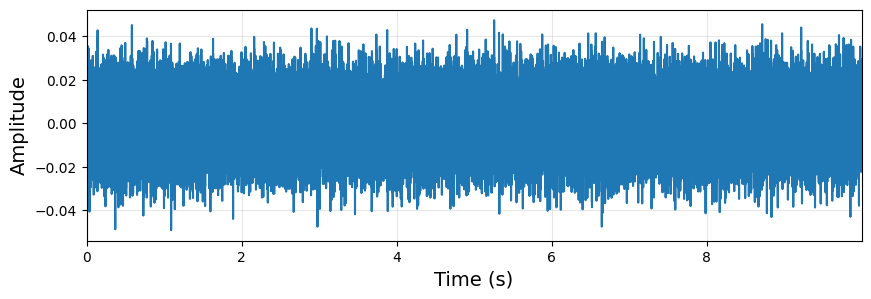

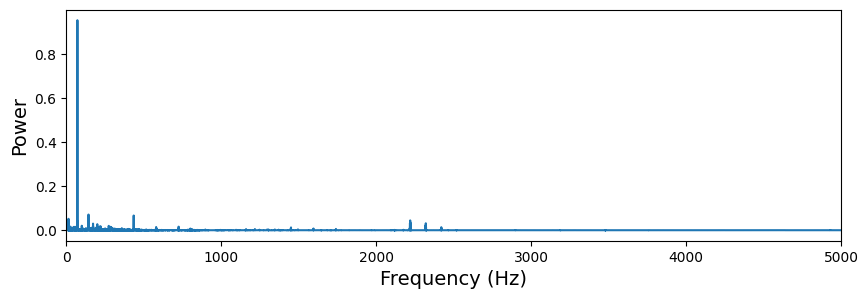

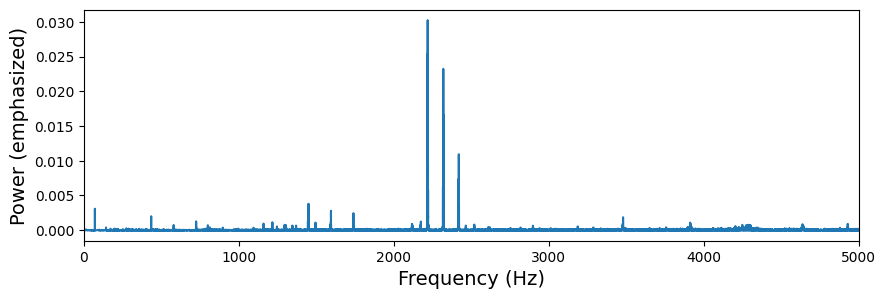

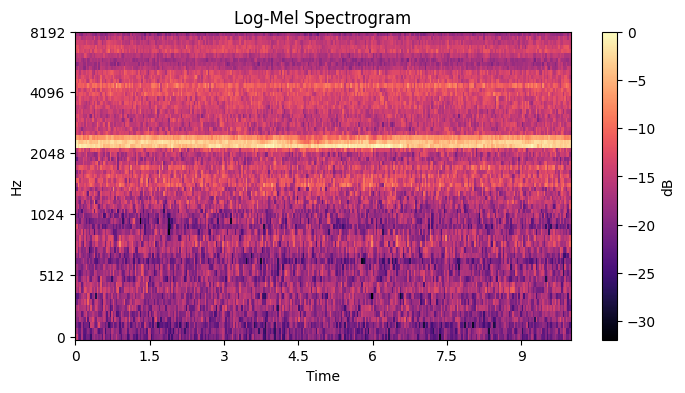

In [56]:
wav_test_file = "data/mimii/dev_data_pump_04/pump/train/normal_id_04_00000000.wav"
# wav_test_file = 'data/mimii/dev_data_pump_04/pump/test/anomaly_id_04_00000000.wav'

# Visualize the features extracted from one sample recording
features = file_to_features(wav_test_file)


### 2. PyTorch Dataset Splitting

In [57]:
class MIMII(Dataset):
    def __init__(
        self, root, machine, train=True, transform=None, target_transform=None
    ):
        machine_type = machine.split("_")[0]
        split = "train" if train else "test"

        self.audio_path = os.path.join(root, f"dev_data_{machine}", machine_type, split)
        self.audio_files = sorted(os.listdir(self.audio_path))
        self.labels = [1 if f.startswith("anomaly") else 0 for f in self.audio_files]
        
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.audio_files)

    def __getitem__(self, idx):
        file_path = os.path.join(self.audio_path, self.audio_files[idx])
        label = self.labels[idx]

        # Feature extraction
        if self.transform:
            features = self.transform(file_path)
        else:
            # Default = log-mel features
            features = file_to_features(file_path).astype(np.float32)

        # Transform lalbel
        if self.target_transform:
            label = self.target_transform(label)
            
        return features, label


In [58]:
# Parameters of the feature extraction
melsp_params = dict(
    n_mels=64, frames=10, n_fft=1024, hop_length=512, power=2.0, plot=False
)


feature_extraction_pipeline = T.Compose(
    [
        T.Lambda(lambda file: file_to_features(file, **melsp_params).astype(np.float32)),
        T.ToTensor(),
    ]
)


In [59]:
# Machine selection
DATA_PATH: str = "./data/mimii/"
MACHINE = "pump_04"  # Choice between  "valve_00" or "pump_04"

# Pytorch train/test datasets
data_train = MIMII(root=DATA_PATH, machine=MACHINE, train=True, transform=feature_extraction_pipeline)

data_test = MIMII(root=DATA_PATH, machine=MACHINE, train=False, transform=feature_extraction_pipeline)


### 3. AutoEncoder Model Definition

In [60]:
class DenseAutoencoder(nn.Module):
    def __init__(self, input_dim):
        super(DenseAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
        )

        # Decoder: symmetrical to the encoder, reconstructs the input
        self.decoder = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim),
        )
    def forward(self, x):
        feature = self.encoder(x)
        reconstruction = self.decoder(feature)
        return reconstruction, feature


In [61]:
duration_sec: int = 10
sampling_rate_hz: int = 16000
input_dim = int(
    np.ceil(duration_sec * sampling_rate_hz / melsp_params["hop_length"] + 1 - melsp_params["frames"])
    * melsp_params["n_mels"] * melsp_params["frames"]
)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

model = DenseAutoencoder(input_dim)
model.to(device)


DenseAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=194560, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=194560, bias=True)
  )
)

### 4. Model Training

In [62]:
# Training parameters
batch_size = 32
epochs = 10

# PyTorch data loaders allow to iterate batch-wise over a dataset
train_loader = DataLoader(data_train, batch_size=batch_size, shuffle=True, drop_last=True)

# Gradient descent optimizer
optimizer = torch.optim.Adam(model.parameters())

# Mean Squared Error (MSE) loss function to be minimized
loss_fn = nn.MSELoss()


In [63]:
def train_loop(dataloader, model, loss_fn, optimizer, print_every=10):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    loss_running = 0
    for batch, (x, y) in enumerate(tqdm(dataloader)):
        # Compute prediction and loss
        x = x.to(device, non_blocking=True).float()
        x = x.flatten(start_dim=1)
        optimizer.zero_grad()
        x_pred, features = model(x)

        # Compute the reconstruction loss, backpropagate and update the parameters
        loss = loss_fn(x_pred, x)
        loss.backward()
        optimizer.step()
        # Back Propagation
        loss_running += loss.item()
    print(f"loss: {loss_running/len(dataloader):>7f}")


def test_loop(dataset, model, loss_fn):
    size = len(dataset)
    test_losses = np.zeros(size)
    store_feature = []
    with torch.no_grad():
        for idx, (x, _) in enumerate(dataset):
            x = x.to(device, non_blocking=True).float()
            x = x.flatten()
            x_pred, features = model(x)
            store_feature.append(features.detach().cpu().numpy())
            test_losses[idx] = loss_fn(x_pred, x).item()

    return test_losses, np.array(store_feature)


In [64]:
for epoch in range(epochs):
    print(f"Epoch {epoch+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, optimizer, print_every=1)


Epoch 1
-------------------------------


  0%|          | 0/18 [00:00<?, ?it/s]

loss: 516.196845
Epoch 2
-------------------------------


  0%|          | 0/18 [00:00<?, ?it/s]

loss: 21.586440
Epoch 3
-------------------------------


  0%|          | 0/18 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/18 [00:00<?, ?it/s]

loss: 12.187094
Epoch 10
-------------------------------


  0%|          | 0/18 [00:00<?, ?it/s]

loss: 12.411964


### 5. Model Evaluation

Accuracy: 0.695
Precision: 0.8305084745762712
Recall: 0.49
F1-Score: 0.6163522012578616


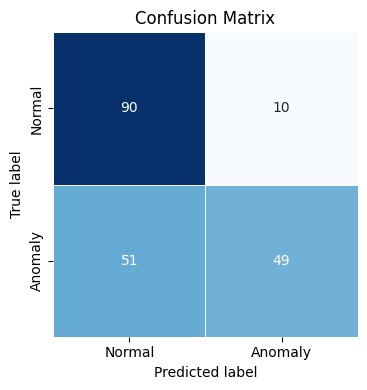


--- Threshold Analysis ---
Percentile 90: Threshold=18.9931, Acc=0.6950, TPR=0.4900, FPR=0.1000, F1=0.6164
Percentile 95: Threshold=21.5953, Acc=0.6450, TPR=0.3300, FPR=0.0400, F1=0.4818
Percentile 99: Threshold=30.1209, Acc=0.5300, TPR=0.0600, FPR=0.0000, F1=0.1132


In [65]:
y_true = data_test.labels
test_losses, extracted_features_test = test_loop(data_test, model, loss_fn)
y_scores = test_losses

metrics.roc_auc_score(y_true, y_scores)

# Threshold on the reconstruction loss, calibrated on healthy training data,
# and standard classification metrics
y_pred_train , extracted_features_train = test_loop(data_train, model, loss_fn)

threshold= np.percentile(y_pred_train, 90)

y_pred=(y_scores > threshold).astype(int)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
conf_matrix = confusion_matrix(y_true, y_pred)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1-Score: {f1}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    square=True,
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"],
    ax=ax,
    linewidths=0.5,
    linecolor="white",
)
ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
fig.tight_layout()
plt.show()

#Comparing different thresholds : 
print(f"\n--- Threshold Analysis ---")
for percentile in [90, 95, 99]:
    thresh = np.percentile(y_pred_train, percentile)
    preds = (y_scores > thresh).astype(int)
    acc = accuracy_score(y_true, preds)
    tpr_val = recall_score(y_true, preds)
    tn_val, fp_val, fn_val, tp_val = confusion_matrix(y_true, preds).ravel()
    fpr_val = fp_val / (fp_val + tn_val) if (fp_val + tn_val) > 0 else 0
    f1_val = f1_score(y_true, preds)
    print(f"Percentile {percentile}: Threshold={thresh:.4f}, Acc={acc:.4f}, TPR={tpr_val:.4f}, FPR={fpr_val:.4f}, F1={f1_val:.4f}")


Text(0.5, 1.0, 'Receiver operating characteristic (ROC) curve for pump_04')

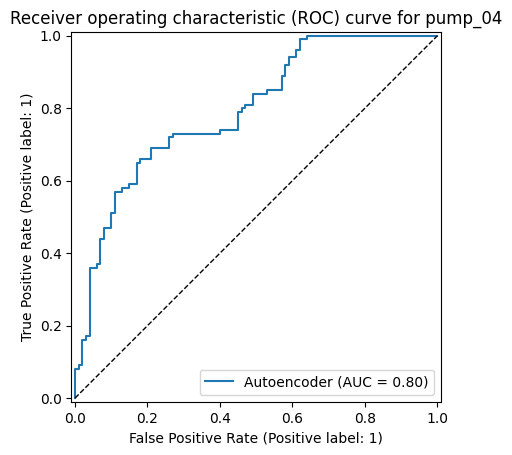

In [66]:
metrics.RocCurveDisplay.from_predictions(y_true, y_scores, name="Autoencoder")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.title(f"Receiver operating characteristic (ROC) curve for {MACHINE}")


### 6. One-Class SVM and Isolation Forest

From the trained AutoEncoder, use the bottleneck features to train a (1) One-Class SVM and (2) Isolation Forest, and report the accuracy, F1-score and auc score of each method.

In [67]:
# Get normal training features
y_pred_train, extracted_features_train = test_loop(data_train, model, loss_fn)


In [68]:
# One-Class SVM fitted on the healthy training features;
# evaluation metrics are reported below

from sklearn.preprocessing import StandardScaler

scaler_ocsvm = StandardScaler()
train_features_scaled = scaler_ocsvm.fit_transform(extracted_features_train)
test_features_scaled = scaler_ocsvm.transform(extracted_features_test)

oc_svm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
oc_svm.fit(train_features_scaled)

# OneClassSVM returns +1 for inliers and -1 for anomalies.
y_pred_ocsvm = (oc_svm.predict(test_features_scaled) == -1).astype(int)
score_ocsvm_bn = oc_svm.decision_function(test_features_scaled).ravel()

ocsvm_accuracy = accuracy_score(y_true, y_pred_ocsvm)
ocsvm_precision = precision_score(y_true, y_pred_ocsvm, zero_division=0)
ocsvm_recall = recall_score(y_true, y_pred_ocsvm, zero_division=0)
ocsvm_f1 = f1_score(y_true, y_pred_ocsvm, zero_division=0)
ocsvm_auc = metrics.roc_auc_score(y_true, -score_ocsvm_bn)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred_ocsvm, labels=[0, 1]).ravel()
ocsvm_fpr = fp / (fp + tn) if (fp + tn) else 0.0

print(f"One-Class SVM Accuracy: {ocsvm_accuracy:.4f}")
print(f"One-Class SVM Precision: {ocsvm_precision:.4f}")
print(f"One-Class SVM Recall / TPR: {ocsvm_recall:.4f}")
print(f"One-Class SVM FPR: {ocsvm_fpr:.4f}")
print(f"One-Class SVM F1-Score: {ocsvm_f1:.4f}")
print(f"One-Class SVM AUC: {ocsvm_auc:.4f}")

metrics.roc_auc_score(y_true, -score_ocsvm_bn)


One-Class SVM Accuracy: 0.5900
One-Class SVM Precision: 0.8214
One-Class SVM Recall / TPR: 0.2300
One-Class SVM FPR: 0.0500
One-Class SVM F1-Score: 0.3594
One-Class SVM AUC: 0.5971


0.5971

In [69]:
# Isolation Forest fitted on the healthy training features;
# evaluation metrics are reported below

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

scaler_iforest = StandardScaler()
train_features_scaled = scaler_iforest.fit_transform(extracted_features_train)
test_features_scaled = scaler_iforest.transform(extracted_features_test)

isolation_forest = IsolationForest(
    n_estimators=200, contamination="auto", random_state=42
 )
isolation_forest.fit(train_features_scaled)

# IsolationForest returns +1 for inliers and -1 for anomalies.
y_pred_iforest = (isolation_forest.predict(test_features_scaled) == -1).astype(int)
score_iso_bn = isolation_forest.decision_function(test_features_scaled).ravel()

iforest_accuracy = accuracy_score(y_true, y_pred_iforest)
iforest_precision = precision_score(y_true, y_pred_iforest, zero_division=0)
iforest_recall = recall_score(y_true, y_pred_iforest, zero_division=0)
iforest_f1 = f1_score(y_true, y_pred_iforest, zero_division=0)
iforest_auc = metrics.roc_auc_score(y_true, -score_iso_bn)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred_iforest, labels=[0, 1]).ravel()
iforest_fpr = fp / (fp + tn) if (fp + tn) else 0.0

print(f"Isolation Forest Accuracy: {iforest_accuracy:.4f}")
print(f"Isolation Forest Precision: {iforest_precision:.4f}")
print(f"Isolation Forest Recall / TPR: {iforest_recall:.4f}")
print(f"Isolation Forest FPR: {iforest_fpr:.4f}")
print(f"Isolation Forest F1-Score: {iforest_f1:.4f}")
print(f"Isolation Forest AUC: {iforest_auc:.4f}")

metrics.roc_auc_score(y_true, -score_iso_bn)


Isolation Forest Accuracy: 0.5750
Isolation Forest Precision: 0.6531
Isolation Forest Recall / TPR: 0.3200
Isolation Forest FPR: 0.1700
Isolation Forest F1-Score: 0.4295
Isolation Forest AUC: 0.6078


0.6078

### 7. Comparison with PCA features

In [70]:
# Extract spectrograms of training and testing
flatten_spectogram_train = []
for idx, (x, _) in enumerate(data_train):
    x = x.flatten()
    flatten_spectogram_train.append(x.numpy())
train_spec = np.array(flatten_spectogram_train)

flatten_spectogram_test = []
for idx, (x, _) in enumerate(data_test):
    x = x.flatten()
    flatten_spectogram_test.append(x.numpy())
test_spec = np.array(flatten_spectogram_test)


In [71]:
pca = PCA(n_components=64)

# Fit PCA on the training spectrograms and project both splits
train_pca = pca.fit_transform(train_spec)
test_pca = pca.transform(test_spec)

In [72]:
# One-Class SVM fitted on the healthy PCA features;
# evaluation metrics are reported below

from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

scaler_pca_ocsvm = StandardScaler()
train_pca_scaled = scaler_pca_ocsvm.fit_transform(train_pca)
test_pca_scaled = scaler_pca_ocsvm.transform(test_pca)

pca_ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
pca_ocsvm.fit(train_pca_scaled)

y_pred_pca_ocsvm = (pca_ocsvm.predict(test_pca_scaled) == -1).astype(int)
score_pca_ocsvm = pca_ocsvm.decision_function(test_pca_scaled).ravel()

pca_ocsvm_accuracy = accuracy_score(y_true, y_pred_pca_ocsvm)
pca_ocsvm_precision = precision_score(y_true, y_pred_pca_ocsvm, zero_division=0)
pca_ocsvm_recall = recall_score(y_true, y_pred_pca_ocsvm, zero_division=0)
pca_ocsvm_f1 = f1_score(y_true, y_pred_pca_ocsvm, zero_division=0)
pca_ocsvm_auc = metrics.roc_auc_score(y_true, -score_pca_ocsvm)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred_pca_ocsvm, labels=[0, 1]).ravel()
pca_ocsvm_fpr = fp / (fp + tn) if (fp + tn) else 0.0

print(f"PCA + One-Class SVM Accuracy: {pca_ocsvm_accuracy:.4f}")
print(f"PCA + One-Class SVM Precision: {pca_ocsvm_precision:.4f}")
print(f"PCA + One-Class SVM Recall / TPR: {pca_ocsvm_recall:.4f}")
print(f"PCA + One-Class SVM FPR: {pca_ocsvm_fpr:.4f}")
print(f"PCA + One-Class SVM F1-Score: {pca_ocsvm_f1:.4f}")
print(f"PCA + One-Class SVM AUC: {pca_ocsvm_auc:.4f}")

metrics.roc_auc_score(y_true, -score_pca_ocsvm)


PCA + One-Class SVM Accuracy: 0.6650
PCA + One-Class SVM Precision: 0.9459
PCA + One-Class SVM Recall / TPR: 0.3500
PCA + One-Class SVM FPR: 0.0200
PCA + One-Class SVM F1-Score: 0.5109
PCA + One-Class SVM AUC: 0.8952


0.8952

In [73]:
# Isolation Forest fitted on the healthy PCA features;
# evaluation metrics are reported below

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

scaler_pca_iforest = StandardScaler()
train_pca_scaled = scaler_pca_iforest.fit_transform(train_pca)
test_pca_scaled = scaler_pca_iforest.transform(test_pca)

pca_iforest = IsolationForest(
    n_estimators=200, contamination="auto", random_state=42
 )
pca_iforest.fit(train_pca_scaled)

y_pred_pca_iforest = (pca_iforest.predict(test_pca_scaled) == -1).astype(int)
score_pca_iforest = pca_iforest.decision_function(test_pca_scaled).ravel()

pca_iforest_accuracy = accuracy_score(y_true, y_pred_pca_iforest)
pca_iforest_precision = precision_score(y_true, y_pred_pca_iforest, zero_division=0)
pca_iforest_recall = recall_score(y_true, y_pred_pca_iforest, zero_division=0)
pca_iforest_f1 = f1_score(y_true, y_pred_pca_iforest, zero_division=0)
pca_iforest_auc = metrics.roc_auc_score(y_true, -score_pca_iforest)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred_pca_iforest, labels=[0, 1]).ravel()
pca_iforest_fpr = fp / (fp + tn) if (fp + tn) else 0.0

print(f"PCA + Isolation Forest Accuracy: {pca_iforest_accuracy:.4f}")
print(f"PCA + Isolation Forest Precision: {pca_iforest_precision:.4f}")
print(f"PCA + Isolation Forest Recall / TPR: {pca_iforest_recall:.4f}")
print(f"PCA + Isolation Forest FPR: {pca_iforest_fpr:.4f}")
print(f"PCA + Isolation Forest F1-Score: {pca_iforest_f1:.4f}")
print(f"PCA + Isolation Forest AUC: {pca_iforest_auc:.4f}")

metrics.roc_auc_score(y_true, -score_pca_iforest)


PCA + Isolation Forest Accuracy: 0.5350
PCA + Isolation Forest Precision: 1.0000
PCA + Isolation Forest Recall / TPR: 0.0700
PCA + Isolation Forest FPR: 0.0000
PCA + Isolation Forest F1-Score: 0.1308
PCA + Isolation Forest AUC: 0.8722


0.8722

### Additional Comparison Plots


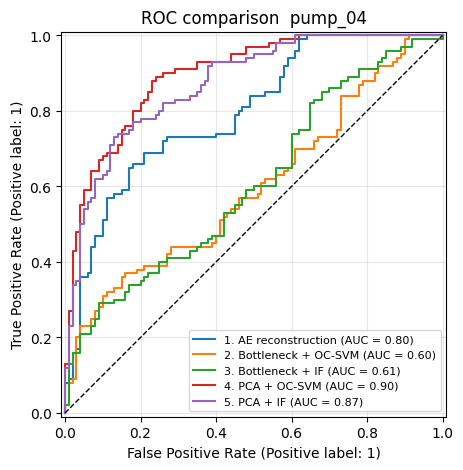

In [74]:
required_scores = {
    "1. AE reconstruction": "y_scores",
    "2. Bottleneck + OC-SVM": "score_ocsvm_bn",
    "3. Bottleneck + IF": "score_iso_bn",
    "4. PCA + OC-SVM": "score_pca_ocsvm",
    "5. PCA + IF": "score_pca_iforest",
}
missing = [name for _, name in required_scores.items() if name not in globals() or globals().get(name) is None]
if missing:
    raise NameError(
        "Missing model score variables for ROC comparison: " + ", ".join(missing) +
        ". Run the earlier model-training cells before plotting ROC curves."
    )

fig, ax = plt.subplots(figsize=(6, 5))
metrics.RocCurveDisplay.from_predictions(y_true, y_scores, name="1. AE reconstruction", ax=ax)
metrics.RocCurveDisplay.from_predictions(y_true, -score_ocsvm_bn, name="2. Bottleneck + OC-SVM", ax=ax)
metrics.RocCurveDisplay.from_predictions(y_true, -score_iso_bn, name="3. Bottleneck + IF", ax=ax)
metrics.RocCurveDisplay.from_predictions(y_true, -score_pca_ocsvm, name="4. PCA + OC-SVM", ax=ax)
metrics.RocCurveDisplay.from_predictions(y_true, -score_pca_iforest, name="5. PCA + IF", ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title(f"ROC comparison  {MACHINE}")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()


In [75]:
# =====================================================================
# Extension: feature fusion - handcrafted features (Part 1)
#            + learned features (Part 2)
# =====================================================================
import time

# ---------- Step 1: handcrafted features (Part I) on the Part II raw audio ----------
# Reuses extract_features() from Part 1 and demux_wav_files() from Part 2.
# Row order follows dataset.audio_files (sorted) -> aligned with y_true,
# extracted_features_test and test_pca.
def handcrafted_matrix(dataset):
    rows = []
    for fname in dataset.audio_files:
        _, y = demux_wav_files(os.path.join(dataset.audio_path, fname), channel=0)
        rows.append(extract_features(y).to_numpy(dtype=np.float64))
    return np.vstack(rows)

hand_train = handcrafted_matrix(data_train)
hand_test  = handcrafted_matrix(data_test)
y_true = np.array(data_test.labels)
print(f"{MACHINE}: handcrafted train {hand_train.shape}, test {hand_test.shape}, "
      f"bottleneck {np.asarray(extracted_features_test).shape}, PCA {np.asarray(test_pca).shape}")

# ---------- Step 2: robust scaling (median / MAD), fitted on the healthy train ----------
def robust_scale(X_train, X_test):
    med = np.median(X_train, axis=0)
    mad = np.median(np.abs(X_train - med), axis=0)
    mad = np.where(mad < 1e-12, 1.0, mad)      # guard against zero MAD
    return (X_train - med) / mad, (X_test - med) / mad

hand_tr_s, hand_te_s = robust_scale(hand_train, hand_test)
bn_tr_s,   bn_te_s   = robust_scale(np.asarray(extracted_features_train, dtype=np.float64),
                                    np.asarray(extracted_features_test,  dtype=np.float64))
pca_tr_s,  pca_te_s  = robust_scale(np.asarray(train_pca, dtype=np.float64),
                                    np.asarray(test_pca, dtype=np.float64))

# ---------- Step 3: concatenation ----------
feature_sets = {
    "hand(6)":      (hand_tr_s, hand_te_s),
    "bn(32)":       (bn_tr_s, bn_te_s),
    "pca(64)":      (pca_tr_s, pca_te_s),
    "fusedAE(38)":  (np.hstack([hand_tr_s, bn_tr_s]),  np.hstack([hand_te_s, bn_te_s])),
    "fusedPCA(70)": (np.hstack([hand_tr_s, pca_tr_s]), np.hstack([hand_te_s, pca_te_s])),
}

# ---------- Step 4: one-class detectors, identical to Part 2 ----------
def evaluate_detector(fs_name, det_kind, X_tr, X_te):
    t0 = time.perf_counter()
    if det_kind == "IF":
        det = IsolationForest(n_estimators=200, contamination="auto", random_state=42)
    else:
        det = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
    det.fit(X_tr)
    fit_s = time.perf_counter() - t0

    s_tr = -det.decision_function(X_tr)          # higher = more anomalous
    s_te = -det.decision_function(X_te)
    y_pred   = (det.predict(X_te) == -1).astype(int)     # default operating point
    tau95    = np.percentile(s_tr, 95)                   # calibrated on healthy train
    y_pred95 = (s_te > tau95).astype(int)

    def prf(y_pred_):
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred_, labels=[0, 1]).ravel()
        tpr = tp / (tp + fn) if (tp + fn) else 0.0
        fpr = fp / (fp + tn) if (fp + tn) else 0.0
        return tpr, fpr, f1_score(y_true, y_pred_, zero_division=0)

    tpr, fpr, f1 = prf(y_pred)
    tpr95, fpr95, f195 = prf(y_pred95)
    return {
        "features": fs_name, "detector": det_kind, "dim": X_tr.shape[1],
        "fit_s": round(fit_s, 3),
        "acc": round(accuracy_score(y_true, y_pred), 4),
        "TPR": round(tpr, 4), "FPR": round(fpr, 4), "F1": round(f1, 4),
        "AUC": round(metrics.roc_auc_score(y_true, s_te), 4),
        "TPR@t95": round(tpr95, 4), "FPR@t95": round(fpr95, 4), "F1@t95": round(f195, 4),
    }

rows = [evaluate_detector(nm, dk, Xtr, Xte)
        for nm, (Xtr, Xte) in feature_sets.items()
        for dk in ("IF", "OC-SVM")]
fusion_results = pd.DataFrame(rows)

print(f"\n===== Feature-fusion results - {MACHINE} =====")
display(fusion_results)
best = fusion_results.loc[fusion_results["AUC"].idxmax()]
print(f"Best AUC:     {best['features']} + {best['detector']} = {best['AUC']:.4f}")
best95 = fusion_results.loc[fusion_results["F1@t95"].idxmax()]
print(f"Best F1@t95:  {best95['features']} + {best95['detector']} = {best95['F1@t95']:.4f}")

pump_04: handcrafted train (602, 6), test (200, 6), bottleneck (200, 32), PCA (200, 64)

===== Feature-fusion results - pump_04 =====


,features,detector,dim,fit_s,acc,TPR,FPR,F1,AUC,TPR@t95,FPR@t95,F1@t95
0,hand(6),IF,6,0.287,0.550,0.16,0.06,0.2623,0.6325,0.15,0.04,0.2521
1,hand(6),OC-SVM,6,0.002,0.545,0.14,0.05,0.2353,0.6232,0.14,0.05,0.2353
2,bn(32),IF,32,0.369,0.575,0.32,0.17,0.4295,0.6078,0.21,0.06,0.3307
3,bn(32),OC-SVM,32,0.002,0.595,0.24,0.05,0.3721,0.6141,0.24,0.05,0.3721
4,pca(64),IF,64,0.434,0.535,0.07,0.00,0.1308,0.8722,0.07,0.00,0.1308
5,pca(64),OC-SVM,64,0.004,0.660,0.34,0.02,0.5000,0.8777,0.34,0.02,0.5000
6,fusedAE(38),IF,38,0.359,0.580,0.29,0.13,0.4085,0.6413,0.21,0.05,0.3333
7,fusedAE(38),OC-SVM,38,0.003,0.580,0.20,0.04,0.3226,0.6134,0.20,0.04,0.3226
8,fusedPCA(70),IF,70,0.298,0.535,0.07,0.00,0.1308,0.8820,0.08,0.00,0.1481
9,fusedPCA(70),OC-SVM,70,0.004,0.570,0.15,0.01,0.2586,0.8768,0.15,0.01,0.2586


Best AUC:     fusedPCA(70) + IF = 0.8820
Best F1@t95:  pca(64) + OC-SVM = 0.5000


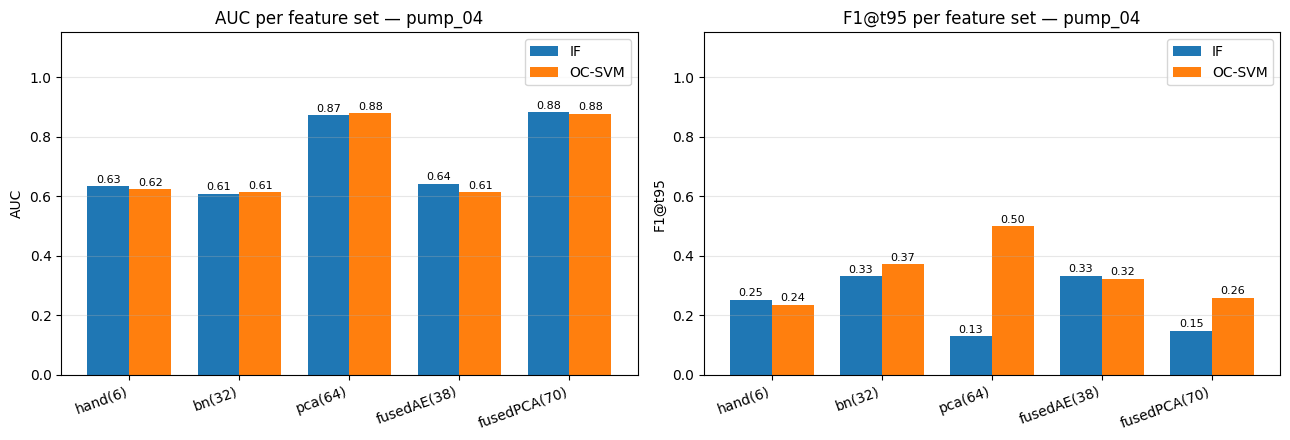

In [76]:
# AUC and calibrated F1 across feature sets
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
names = list(feature_sets)
x = np.arange(len(names)); w = 0.38
for ax, col in zip(axes, ("AUC", "F1@t95")):
    for k, dk in enumerate(("IF", "OC-SVM")):
        vals = fusion_results.loc[fusion_results["detector"] == dk, col].to_numpy()
        ax.bar(x + (k - 0.5) * w, vals, w, label=dk)
        ax.bar_label(ax.containers[k], fmt="%.2f", fontsize=8, padding=1)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylim(0, 1.15); ax.set_ylabel(col)
    ax.set_title(f"{col} per feature set - {MACHINE}")
    ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); plt.show()